# Local Matching for Wikidata

Finds duplicate records **within** the normalized Wikidata airport dataset (`wikidataNormalized.csv`) — the same real-world airport stored as more than one row.

Blocking needs both a `countryCode` and a distinguishing `name` token to work the way it's designed (step 2) — not every record has both, so records are split into three groups and handled separately:

- **Group A** — has `countryCode` **and** a distinguishing `name` token (23,764 records, 95.6%). The main pipeline.
- **Group B** — has `countryCode` **but no** distinguishing `name` token (1,074 records, 4.3%). Generic names (e.g. `"smith ranch airport"`); blocked by `countryCode` + a staggered coordinate grid instead.
- **Group C** — has a distinguishing `name` token **but no** `countryCode` (20 records, <0.1%). Too few to need a blocking pipeline — listed directly.


**Shared step**
1. Load the normalized dataset

**Group A steps**

2. Blocking key: `countryCode` + distinguishing `name` tokens
3. Filter candidates: no self-pairs, no reversed duplicates
4. Per-attribute comparators (name, city, geo distance, icao, iata)
5. Score candidates with `RuleBasedMatcher`
6. Score distribution
7. Manual review of high-scoring candidates

**Group B steps** 

2. Block by `countryCode` + a staggered coordinate grid, against the whole dataset
3. Filter candidates
4. Score candidates
5. Manual review
6. Note: `countryCode`+`city` and a `BallTree` radius search were also tried

**Group C steps**

2. List the 20 records directly
3. Sanity-check against the whole dataset (no country restriction)

**Not done yet:** deciding how to resolve the duplicates found (merge, flag, remove, ...).

**One record (`wd_2159`, `"villa airstrip"`) has neither and isn't covered by any group** — not enough signal for any automated approach, accepted as a known gap.

## 1. Load the normalized dataset (shared by all groups)

In [86]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path("../../data/normalized_outputs")
INPUT_CSV = DATA_DIR / "wikidataNormalized.csv"

df = pd.read_csv(INPUT_CSV, keep_default_na=False, na_values=[""])
df.attrs["source"] = "wikidata"

print(f"Loaded {len(df)} records")
print(f"Columns: {list(df.columns)}")
df.head(5)

Loaded 24859 records
Columns: ['id', 'name', 'iata', 'icao', 'lat', 'lon', 'elevation', 'countryName', 'city', 'wikidataURI', 'operator', 'timezone', 'owner', 'localCode', 'countryCode']


,id,name,iata,icao,lat,lon,elevation,countryName,city,wikidataURI,operator,timezone,owner,localCode,countryCode
0,wd_1,jian jinggangshan airport,JGS,ZSGS,26.857500,114.737222,86.0000,peoples republic of china,taihe county,http://www.wikidata.org/entity/Q1000018,NaN,NaN,NaN,NaN,CN
1,wd_2,changde taohuayuan airport,CGD,ZGCD,28.918900,111.640000,NaN,peoples republic of china,hunan,http://www.wikidata.org/entity/Q1000025,NaN,NaN,NaN,NaN,CN
2,wd_3,jiujiang lushan airport,JIU,ZSJJ,29.476944,115.801111,49.9872,peoples republic of china,jiujiang,http://www.wikidata.org/entity/Q1002604,NaN,NaN,NaN,NaN,CN
3,wd_4,aksu hongqipo airport,AKU,ZWAK,41.262500,80.291667,1163.0000,peoples republic of china,hongqipo,http://www.wikidata.org/entity/Q1006478,NaN,NaN,NaN,NaN,CN
4,wd_5,mohe gulian airport,OHE,ZYMH,52.921111,122.420556,579.0000,peoples republic of china,heilongjiang,http://www.wikidata.org/entity/Q1006900,NaN,NaN,NaN,NaN,CN


## Group A — 2. Blocking key: `countryCode` + distinguishing `name` tokens

- Goal: generate candidate duplicate pairs by self-blocking (the dataset against itself) without `name`'s generic words (`airport`, `ranch`, common surnames, ...) or the unreliable `city` field (often a state/province, not a real city) blowing up block sizes.

- Method: `TokenBlocker` on `name`, with a data-derived (document-frequency) common-word exclusion list, and `countryCode` baked into each token (`"CN::jian"`) so blocking and the country check happen in one pass.

Records this can't reach (Group B/C) are handled further down.

In [87]:
# Hand-picking generic words (airport, international, ...) was not enough: common
# rural/geographic filler words (ranch: 1084 rows, lake: 395, creek: 254, ...) and common
# surnames (smith, johnson, williams, ...) are just as damaging to block sizes.
# Instead, derive the exclusion list straight from the data: any token that appears in
# more than COMMON_TOKEN_THRESHOLD distinct names is treated as non-distinguishing.

from collections import Counter

COMMON_TOKEN_THRESHOLD = 20 # trade-off between threshhold and number of common words 

token_doc_freq = Counter()

for name in df["name"].dropna():
    token_doc_freq.update(set(t for t in name.split() if len(t) >= 2))

COMMON_TOKENS = {t for t, c in token_doc_freq.items() if c > COMMON_TOKEN_THRESHOLD}
print(f"Excluding {len(COMMON_TOKENS)} tokens that each appear in more than {COMMON_TOKEN_THRESHOLD} names")

def blocking_tokenizer(text):
    if not isinstance(text, str):
        return []
    return [t for t in text.split() if len(t) >= 2 and t not in COMMON_TOKENS]

sample_tokens = df["name"].dropna().head(5).apply(blocking_tokenizer)

print("\nExample tokens kept for blocking:")

for name, toks in zip(df["name"].dropna().head(5), sample_tokens):
    print(f"  {name!r:40s} -> {toks}")

no_tokens_left = df["name"].apply(lambda n: len(blocking_tokenizer(n)) == 0)

print(f"\n{no_tokens_left.sum()} records ({no_tokens_left.mean():.1%}) have no distinguishing token left "
      "and therefore cannot be blocked at all with this strategy (known coverage gap).")


# those left no distinguishing tokens would apply another blocking method 

Excluding 152 tokens that each appear in more than 20 names

Example tokens kept for blocking:
  'jian jinggangshan airport'              -> ['jian', 'jinggangshan']
  'changde taohuayuan airport'             -> ['changde', 'taohuayuan']
  'jiujiang lushan airport'                -> ['jiujiang', 'lushan']
  'aksu hongqipo airport'                  -> ['aksu', 'hongqipo']
  'mohe gulian airport'                    -> ['mohe', 'gulian']

1075 records (4.3%) have no distinguishing token left and therefore cannot be blocked at all with this strategy (known coverage gap).


In [88]:
# Combine countryCode into the blocking text so a single TokenBlocker call enforces
# "same country AND shares a distinguishing word" -- see step 2 markdown.
# A record with no countryCode or no name gets None -> no tokens -> can't be blocked

def make_blocking_text(row):
    if pd.isna(row["countryCode"]) or pd.isna(row["name"]):
        return None
    return f"{row['countryCode']}||{row['name']}"

df["name_with_country"] = df.apply(make_blocking_text, axis=1)

def country_scoped_tokenizer(text):
    if not isinstance(text, str):
        return []
    country, _, name = text.partition("||")
    tokens = [t for t in name.split() if len(t) >= 2 and t not in COMMON_TOKENS]
    return [f"{country}::{t}" for t in tokens]

from PyDI.entitymatching import TokenBlocker

blocker = TokenBlocker(
    df_left=df,
    df_right=df,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates = blocker.materialize()
print(f"Raw candidate pairs from token blocking: {len(candidates)}")
print(blocker.stats())
candidates.head(10)

Raw candidate pairs from token blocking: 78376
{'pairs_emitted': 78376, 'batches_emitted': 1, 'batch_size': 100000}


,id1,id2
0,wd_1,wd_1
1,wd_2,wd_2
2,wd_3,wd_3
3,wd_4,wd_4
4,wd_5,wd_5
5,wd_6,wd_6
6,wd_7,wd_7
7,wd_8,wd_8
8,wd_9,wd_9
9,wd_10,wd_10


## Group A — 3. Filter candidates: no self-pairs, no reversed duplicates

- Goal: remove the noise self-blocking produces. 
- Method: drop `id1 == id2`, and keep one canonical direction per pair (`id1 < id2`) to drop `(A,B)`/`(B,A)` duplicates.

In [89]:
# Drop self-pairs
candidates = candidates[candidates["id1"] != candidates["id2"]].copy()

# Keep one canonical direction per pair (id1 < id2) to drop reversed duplicates
swap = candidates["id1"] > candidates["id2"]
candidates.loc[swap, ["id1", "id2"]] = candidates.loc[swap, ["id2", "id1"]].values
candidates = candidates.drop_duplicates(subset=["id1", "id2"])

candidates = candidates.reset_index(drop=True)
print(f"Candidate pairs after filtering: {len(candidates)}")
candidates.head(10)

Candidate pairs after filtering: 27306


,id1,id2
0,wd_10,wd_17199
1,wd_13,wd_16187
2,wd_14,wd_3268
3,wd_1093,wd_25
4,wd_29,wd_6635
5,wd_30,wd_4654
6,wd_30,wd_5782
7,wd_11416,wd_30
8,wd_11417,wd_30
9,wd_11418,wd_30


## Group A — 4. Per-attribute comparators

Goal: a similarity score per attribute for each candidate pair. Method:

- `name`, `city`: Jaro-Winkler string similarity
- `lat`/`lon`: one `GeoDistanceComparator` (Haversine great-circle distance, `max_distance_km=2.0`), not two independent degree-difference comparators — degrees of longitude shrink with latitude, and this dataset has high-latitude airports. `2km` (not a looser value like 50km) because known-different airports in this dataset sit 2-5km apart and would otherwise still score 0.90+.
- `icao`, `iata`: custom `CodeComparator` — exact match, but neutral (`0.5`) when either side is missing, instead of the built-in `StringComparator`'s `0.0` (which would treat "no code recorded" as "confidently not a duplicate")

These comparators/weights are reused by Group B further down.

In [90]:
import math

from PyDI.entitymatching import StringComparator
from PyDI.entitymatching.base import BaseComparator

# name: tolerant of small spelling differences
name_comp = StringComparator(column="name", similarity_function="jaro_winkler")

# city: same metric, weighted lower later (see markdown above)
city_comp = StringComparator(column="city", similarity_function="jaro_winkler")

# lat/lon: great-circle (Haversine) distance between the two points, not two
# independent degree-difference comparators (see markdown above for why).
class GeoDistanceComparator(BaseComparator):
    """Great-circle (Haversine) distance between two lat/lon points, converted to similarity."""

    def __init__(self, lat_column="lat", lon_column="lon", max_distance_km=10.0):
        super().__init__(name="geo_distance")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.max_distance_km = max_distance_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
            return 0.5  # neutral: can't compute without both coordinates
        distance_km = self._haversine_km(lat1, lon1, lat2, lon2)
        return max(0.0, 1.0 - distance_km / self.max_distance_km)

    @staticmethod
    def _haversine_km(lat1, lon1, lat2, lon2):
        R = 6371.0  # Earth radius in km
        phi1, phi2 = math.radians(lat1), math.radians(lat2)
        dphi = math.radians(lat2 - lat1)
        dlambda = math.radians(lon2 - lon1)
        a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
        return 2 * R * math.asin(math.sqrt(a))

geo_comp = GeoDistanceComparator(max_distance_km=2.0)

# iata/icao: custom comparator with neutral handling of missing values
# (see markdown above for why the built-in StringComparator is not used here).
# RuleBasedMatcher calls `comparator.compare(record1, record2)` directly, so this
# must subclass BaseComparator -- a plain function would not work here.

class CodeComparator(BaseComparator):
    """Exact-match comparator for a code column (iata/icao), neutral on missing values."""

    def __init__(self, column):
        super().__init__(name=f"{column}_exact")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if pd.isna(v1) or pd.isna(v2):
            return 0.5  # neutral: no evidence either way
        return 1.0 if v1 == v2 else 0.0

icao_comp = CodeComparator("icao")
iata_comp = CodeComparator("iata")

comparators = [name_comp, city_comp, geo_comp, icao_comp, iata_comp]
comparator_names = ["name", "city", "geo_distance", "icao", "iata"]

# Quick sanity check: compare the first candidate pair field by field
row = candidates.iloc[0]
r1 = df.set_index("id").loc[row["id1"]]
r2 = df.set_index("id").loc[row["id2"]]
for cname, comp in zip(comparator_names, comparators):
    print(f"  {cname:<12} -> {comp.compare(r1, r2):.2f}")

  name         -> 0.76
  city         -> 0.79
  geo_distance -> 0.00
  icao         -> 0.00
  iata         -> 0.00


## Group A — 5. Score candidates with `RuleBasedMatcher`

- Goal: combine the per-attribute scores into one score per pair. 

- Method: weighted sum (`name` highest, `city` lowest — see step 2 — others medium), `threshold=0.0` to keep every score for now and pick a real cutoff from the distribution instead of guessing.

In [91]:
from PyDI.entitymatching import RuleBasedMatcher

weights = [0.35, 0.10, 0.30, 0.15, 0.10]  # name, city, geo_distance, icao, iata

matcher = RuleBasedMatcher()
correspondences, debug_results = matcher.match(
    df_left=df,
    df_right=df,
    candidates=candidates[["id1", "id2"]],
    id_column="id",
    comparators=comparators,
    weights=weights,
    threshold=0.0,  # keep everything for now, see step 6 for the score distribution
    debug=True,
)

print(f"Scored {len(correspondences)} candidate pairs")
correspondences.head(10)

Scored 27306 candidate pairs


,id1,id2,score,notes
0,wd_10,wd_17199,0.346247,comparators=5
1,wd_13,wd_16187,0.682232,comparators=5
2,wd_14,wd_3268,0.479514,comparators=5
3,wd_1093,wd_25,0.391370,comparators=5
4,wd_29,wd_6635,0.537273,comparators=5
5,wd_30,wd_4654,0.340920,comparators=5
6,wd_30,wd_5782,0.309761,comparators=5
7,wd_11416,wd_30,0.468598,comparators=5
8,wd_11417,wd_30,0.456159,comparators=5
9,wd_11418,wd_30,0.461873,comparators=5


## Group A — 6. Score distribution

- Goal: see whether there's a natural gap between likely duplicates and likely blocking false positives before picking a threshold. 

- Method: histogram of all candidate scores.

count    27306.000000
mean         0.439450
std          0.064421
min          0.201193
25%          0.402393
50%          0.439579
75%          0.482824
max          0.865882
Name: score, dtype: float64


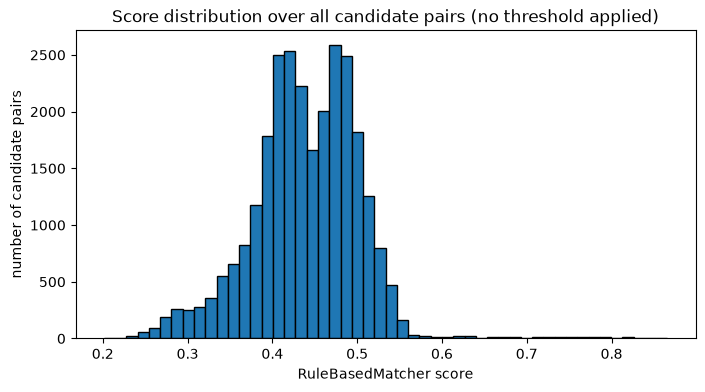

In [92]:
import matplotlib.pyplot as plt

print(correspondences["score"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correspondences["score"], bins=50, edgecolor="black")
ax.set_xlabel("RuleBasedMatcher score")
ax.set_ylabel("number of candidate pairs")
ax.set_title("Score distribution over all candidate pairs (no threshold applied)")
plt.show()

## Group A — 7. Manual review of high-scoring candidates

Goal: check whether the matcher's top-scoring pairs are real duplicates. Method: list every candidate with `score > 0.6` alongside `name`/`city`/`icao`/`iata` for manual inspection.

Threshold chosen from known cases (geo_distance at 2km, see step 4): known likely-duplicates score 0.75-0.78, known non-duplicates score 0.45-0.49 — `0.6` sits in between with margin on both sides. Reused as-is for Group B/C below.

In [93]:
SCORE_THRESHOLD = 0.6

name_city_icao = df.set_index("id")[["name", "city", "icao", "iata"]]

review = (
    correspondences[correspondences["score"] > SCORE_THRESHOLD]
    .sort_values("score", ascending=False)
    .join(name_city_icao.add_suffix("1"), on="id1")
    .join(name_city_icao.add_suffix("2"), on="id2")
)

print(f"{len(review)} candidate pairs with score > {SCORE_THRESHOLD}")
review[["id1", "id2", "name1", "name2", "city1", "city2", "icao1", "icao2", "iata1", "iata2", "score"]]

231 candidate pairs with score > 0.6


,id1,id2,name1,name2,city1,city2,icao1,icao2,iata1,iata2,score
17526,wd_11146,wd_23274,hickory ridge airport,hickory ridge airport,jefferson county,jefferson county,NaN,NaN,NaN,NaN,0.865882
23704,wd_11572,wd_11574,ken guidry nr 1 airport,ken guidry number 1 airport,vermilion parish,vermilion parish,NaN,NaN,NaN,NaN,0.862798
24105,wd_18175,wd_23311,diamond star ranch airport,diamond star ranch airport,huerfano county,huerfano county,NaN,NaN,NaN,NaN,0.858324
21763,wd_10465,wd_23395,five oaks estate airport,five oaks estate airport,okaloosa county,okaloosa county,NaN,NaN,NaN,NaN,0.855561
25042,wd_13401,wd_23479,rhea rla airport,rhea rla airport,hancock county,hancock county,NaN,NaN,NaN,NaN,0.852465
...,...,...,...,...,...,...,...,...,...,...,...
6175,wd_16746,wd_2380,flin flon bakers narrows water aerodrome,flin flon airport,manitoba,manitoba,NaN,CYFO,NaN,YFO,0.609201
24861,wd_12968,wd_12969,paynesville,paynesville municipal airport,minnesota,stearns county,NaN,KPEX,NaN,NaN,0.608544
26025,wd_14684,wd_23578,utley airport,utley airport,bastrop county,anderson county,NaN,NaN,NaN,NaN,0.606052
26555,wd_16809,wd_21645,lac bonnet airport,lac bonnet north water aerodrome,manitoba,manitoba,CYAX,NaN,NaN,NaN,0.605177


## Groups B and C: records Group A's pipeline can't reach

**Group B** — `countryCode` present, no distinguishing `name` token (1,074 records). Handled below.

**Group C** — distinguishing `name` token present, `countryCode` missing (20 records). Listed directly further down.

## Group B: block by a staggered `countryCode` + coordinate grid

Goal: generate candidate pairs for Group B, against the whole dataset (not just Group B — a duplicate could have a distinguishing name on the other side, in Group A).

Method: round `lat`/`lon` to ~2km tiles and use `TokenBlocker` the same way step 2 uses word tokens, except the "tokens" are grid-tile IDs (`countryCode` baked in, same trick as step 2). Each record gets **4 overlapping tiles** (normal grid + one offset by half a tile in both directions) instead of 1, so two points near a tile edge still share a tile instead of being split apart. `countryCode`+`city` was tried first — see the note at the end of this section for why it was dropped.

Example — `johnson landing strip` (`wd_11503`, `countryCode="US"`, `lat=41.384`, `lon=-87.945`):

```
GRID_DEG = 2.0 / 111.0 ≈ 0.018018
lat / GRID_DEG = 2296.839     lon / GRID_DEG = -4880.920

(dlat=0.0, dlon=0.0) -> floor(2296.839, -4880.920) -> (2296, -4881) -> "US::2296_-4881"
(dlat=0.0, dlon=0.5) -> floor(2296.839, -4880.420) -> (2296, -4881) -> "US::2296_-4881"  (same tile)
(dlat=0.5, dlon=0.0) -> floor(2297.339, -4880.920) -> (2297, -4881) -> "US::2297_-4881"
(dlat=0.5, dlon=0.5) -> floor(2297.339, -4880.420) -> (2297, -4881) -> "US::2297_-4881"  (same tile)
```

Only 2 distinct tiles here (not 4) — this record's longitude happens to land where the normal and offset grids agree, so that direction contributes nothing new. That's fine: `TokenBlocker` just needs *any* shared tile, duplicate tokens don't cause problems. Any other record falling in either `"US::2296_-4881"` or `"US::2297_-4881"` becomes a candidate.

In [ ]:
# no_tokens_left was computed in step 2 from plain name tokens (no country prefix)
group_b = df[no_tokens_left & df["countryCode"].notna()].copy()
print(f"Group B: {len(group_b)} records")

GRID_SIZE_KM = 2.0
GRID_DEG = GRID_SIZE_KM / 111.0  # rough deg-per-km; fine for blocking (not for measuring)

def geo_tokens(row):
    if pd.isna(row["lat"]) or pd.isna(row["lon"]) or pd.isna(row["countryCode"]):
        return []
    tokens = []
    for dlat in (0.0, 0.5):      # normal grid + grid offset by half a tile
        for dlon in (0.0, 0.5):
            cell_lat = math.floor(row["lat"] / GRID_DEG + dlat)
            cell_lon = math.floor(row["lon"] / GRID_DEG + dlon)
            tokens.append(f"{row['countryCode']}::{cell_lat}_{cell_lon}")
    return tokens

# TokenBlocker's tokenizer only sees one column's text, so precompute the 4 tile IDs
# per record and look them up by id (the "text" column is just each record's own id).
df["geo_grid_tokens"] = df.apply(geo_tokens, axis=1)
grid_token_lookup = df.set_index("id")["geo_grid_tokens"].to_dict()

def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])

df["id_as_text"] = df["id"]
group_b["id_as_text"] = group_b["id"]

blocker_b = TokenBlocker(
    df_left=group_b,
    df_right=df,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
)

candidates_b = blocker_b.materialize()
print(f"Raw candidate pairs: {len(candidates_b)}")
candidates_b.head(10)

### Filter Group B candidates: no self-pairs, no reversed duplicates

Same as step 3.

In [95]:
candidates_b = candidates_b[candidates_b["id1"] != candidates_b["id2"]].copy()

swap = candidates_b["id1"] > candidates_b["id2"]
candidates_b.loc[swap, ["id1", "id2"]] = candidates_b.loc[swap, ["id2", "id1"]].values
candidates_b = candidates_b.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"Candidate pairs after filtering: {len(candidates_b)}")
candidates_b.head(10)

Candidate pairs after filtering: 59946


,id1,id2
0,wd_17530,wd_205
1,wd_18942,wd_205
2,wd_19761,wd_205
3,wd_205,wd_23567
4,wd_17530,wd_19761
5,wd_18942,wd_19761
6,wd_19761,wd_23567
7,wd_206,wd_38
8,wd_206,wd_247
9,wd_206,wd_314


### Score Group B candidates

Same `comparators` as Group A, own weighting (`weights_b`): `name`/`city` down (weak signal here, see step 2), `geo_distance` up (the real signal, and now what blocking itself is built on).

In [ ]:
weights_b = [0.20, 0.05, 0.50, 0.15, 0.10]  # name, city, geo_distance, icao, iata

matcher_b = RuleBasedMatcher()
correspondences_b, debug_results_b = matcher_b.match(
    df_left=df,
    df_right=df,
    candidates=candidates_b[["id1", "id2"]],
    id_column="id",
    comparators=comparators,
    weights=weights_b,
    threshold=0.0,
    debug=True,
)

print(f"Scored {len(correspondences_b)} candidate pairs")
print(correspondences_b["score"].describe())

### Manual review of Group B candidates

Same `score > 0.6` threshold as step 7. `geo_verified` kept as a sanity check — should read `True` for everything, since blocking itself now requires real coordinates on both sides.

In [97]:
coords = df.set_index("id")[["lat", "lon"]]

review_b = (
    correspondences_b[correspondences_b["score"] > SCORE_THRESHOLD]
    .sort_values("score", ascending=False)
    .join(name_city_icao.add_suffix("1"), on="id1")
    .join(name_city_icao.add_suffix("2"), on="id2")
    .join(coords.add_suffix("1"), on="id1")
    .join(coords.add_suffix("2"), on="id2")
)
review_b["geo_verified"] = review_b[["lat1", "lon1", "lat2", "lon2"]].notna().all(axis=1)

print(f"{len(review_b)} candidate pairs with score > {SCORE_THRESHOLD}")
review_b[["id1", "id2", "name1", "name2", "city1", "city2", "icao1", "icao2", "iata1", "iata2", "geo_verified", "score"]]

30 candidate pairs with score > 0.6


,id1,id2,name1,name2,city1,city2,icao1,icao2,iata1,iata2,geo_verified,score
58932,wd_19784,wd_19785,sky ranch north airport,sky ranch south airport,canyon county,canyon county,NaN,NaN,NaN,NaN,True,0.827685
28001,wd_6673,wd_6677,bar river water aerodrome,bar river airport,ontario,ontario,NaN,CPF2,NaN,YEB,True,0.754900
63,wd_206,wd_22412,smith mountain lake airport,new river valley airport,virginia,virginia,NaN,KPSK,NaN,PSK,True,0.746154
51508,wd_11503,wd_8732,johnson landing strip,clarence c johnson airport,will county,will county,NaN,NaN,NaN,NaN,True,0.737136
1,wd_18942,wd_205,lazy f ranch airport,smith mountain ranch airport,wallowa county,wallowa county,NaN,NaN,NaN,NaN,True,0.727773
58879,wd_19978,wd_23358,flying z airport,flying z airport,pueblo county,pueblo county,NaN,NaN,NaN,NaN,True,0.721012
52555,wd_19577,wd_23589,river view airpark,riverview airpark airport,douglas county,douglas county,NaN,NaN,NaN,NaN,True,0.700646
48322,wd_23583,wd_8833,flying j airport,brushy creek airport,grayson county,grayson county,NaN,NaN,NaN,NaN,True,0.686062
48491,wd_10231,wd_8103,e i landing strip,185 monmouth parkway associates helistop,monmouth county,monmouth county,NaN,NaN,NaN,NaN,True,0.685727
41529,wd_12569,wd_5794,municipal airport,lawton fort sill regional airport,oklahoma,oklahoma,NaN,KLAW,NaN,LAW,True,0.682312


### Note: two other blocking keys considered for Group B

**`countryCode` + `city`** (`StandardBlocker`, exact match, whole dataset): cheap-ish (~60,000 pairs) and found real duplicates, but missed 21 of Group B's 1,074 records entirely whenever the match used a different `city` granularity (`"texas"` vs the actual town) — `city` is exactly the field step 2 already distrusts for this reason. Also let through false positives when both sides lacked coordinates (`geo_distance` falls back to neutral `0.5`, so `city` + two neutrals alone could clear the threshold).

**`sklearn.neighbors.BallTree`** (`metric="haversine"`, radius search): no discrete key at all — indexes `(lat, lon)` directly and queries "within 2km". More precise than the grid (exact distance, no tile-shape artifacts) and found the same candidates (88 vs 83). Not used here only because it doesn't produce an `(id1, id2)` table the way `TokenBlocker`/`StandardBlocker` do:

```python
import numpy as np
from sklearn.neighbors import BallTree

EARTH_RADIUS_KM = 6371.0
coords = df.dropna(subset=["lat", "lon", "countryCode"])
tree = BallTree(np.radians(coords[["lat", "lon"]].values), metric="haversine")

gb_coords = group_b.dropna(subset=["lat", "lon", "countryCode"])
neighbor_idx = tree.query_radius(np.radians(gb_coords[["lat", "lon"]].values), r=2.0 / EARTH_RADIUS_KM)
# still needs a countryCode post-filter and id1/id2 pair construction
```

## Group C: just look at the 20 records

Only 20 records, so a blocking pipeline is overkill — list them directly.

Most are missing `countryCode` because `countryName` is a historical/disputed entity that `wikidata_normalization.ipynb` deliberately nulled out (`luhansk peoples republic`, `republic of abkhazia`, `trucial states`, `german reich`, `british raj`), or because there's no `countryName` at all.

In [98]:
group_c = df[df["countryCode"].isna() & df["name"].apply(lambda n: len(blocking_tokenizer(n)) > 0)]

print(f"Group C: {len(group_c)} records")
group_c[["id", "name", "city", "countryName", "lat", "lon", "icao", "iata"]]

Group C: 20 records


,id,name,city,countryName,lat,lon,icao,iata
2159,wd_2160,saldanha airport,NaN,NaN,-32.963333,17.970000,NaN,NaN
2161,wd_2162,nagaki ruzaphema international airport,NaN,NaN,NaN,NaN,NaN,NaN
2162,wd_2163,tourou international airport,NaN,NaN,9.391750,2.507667,NaN,NaN
2192,wd_2193,ambala domestic airport,NaN,NaN,30.370833,76.817778,NaN,NaN
2197,wd_2198,waterville regional airport,NaN,NaN,44.533333,-69.675556,NaN,NaN
2201,wd_2202,atlantic aerodrome,NaN,NaN,-33.588195,18.618167,FAAA,NaN
2213,wd_2214,kolkata kalyani airport,NaN,NaN,22.654722,88.446667,NaN,NaN
2217,wd_2218,amaravati international airport,NaN,NaN,16.465000,80.426944,NaN,NaN
2223,wd_2224,west subiaco aerodrome,NaN,NaN,-31.953889,115.787500,NaN,NaN
2224,wd_2225,gaborones airport,NaN,NaN,-24.655556,25.939722,NaN,NaN


Sanity check: do any of these 20 share a distinguishing `name` token with anything else in the dataset (no country restriction, since that's exactly what Group C is missing)? Same `TokenBlocker` as Group A's step 2, just `df_left=group_c` (not the whole dataset) and no country prefix on the tokens. Scored against the same `comparators`/`weights` as Group A/B.

In [99]:
blocker_c = TokenBlocker(
    df_left=group_c,
    df_right=df,
    column="name",
    id_column="id",
    tokenizer=blocking_tokenizer,
)

candidates_c = blocker_c.materialize()
candidates_c = candidates_c[candidates_c["id1"] != candidates_c["id2"]].copy()

# Canonicalize pair order before dedup (same as Group A/B) -- df_left=group_c is a
# subset of df_right=df, so two group_c records sharing a token would otherwise show
# up as both (A,B) and (B,A). Currently never triggered (no two of the 20 collide),
# but kept for consistency/robustness.
swap = candidates_c["id1"] > candidates_c["id2"]
candidates_c.loc[swap, ["id1", "id2"]] = candidates_c.loc[swap, ["id2", "id1"]].values
candidates_c = candidates_c.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)
print(f"Candidate pairs: {len(candidates_c)}")

matcher_c = RuleBasedMatcher()
correspondences_c, debug_results_c = matcher_c.match(
    df_left=df,
    df_right=df,
    candidates=candidates_c[["id1", "id2"]],
    id_column="id",
    comparators=comparators,
    weights=weights,
    threshold=0.0,
    debug=True,
)

print(f"Best candidate score found: {correspondences_c['score'].max():.2f} (threshold used elsewhere: {SCORE_THRESHOLD})")
correspondences_c.sort_values("score", ascending=False).head(10)

Candidate pairs: 47
Best candidate score found: 0.77 (threshold used elsewhere: 0.6)


,id1,id2,score,notes
19,wd_2198,wd_24203,0.775000,comparators=5
1,wd_17348,wd_2193,0.728570,comparators=5
0,wd_2160,wd_5373,0.717248,comparators=5
35,wd_22118,wd_2485,0.507397,comparators=5
27,wd_17106,wd_2942,0.466166,comparators=5
18,wd_2198,wd_24202,0.443889,comparators=5
24,wd_2227,wd_32,0.442431,comparators=5
26,wd_1141,wd_2228,0.440412,comparators=5
25,wd_2227,wd_5381,0.428990,comparators=5
17,wd_16702,wd_2198,0.422898,comparators=5
